<a href="https://colab.research.google.com/github/ja2faded/A01-data-wrangling/blob/main/A3notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment 3: $k$ Nearest Neighbor


**Q1.**
1. What is the difference between regression and classification?
2. What is a confusion table? What does it help us understand about a model's performance?
3. What does the SSE quantify about a particular model?
4. What are overfitting and underfitting?
5. Why does splitting the data into training and testing sets, and choosing $k$ by evaluating accuracy or SSE on the test set, improve model performance?
6. With classification, we can report a class label as a prediction or a probability distribution over class labels. Please explain the strengths and weaknesses of each approach.

1. Regression predicts a continuous output (such as price), while classification predicts a discrete output (such as yes vs no)
2. A confusion table cross-tabulates what the model predicted vs what actually happened. It helps us understand how the model was inaccurate (false positive vs false negative, etc.) rather than strictly an accuracy value.
3. For a model, SSE is the sum of all (actual-predicted)^2. It is a measurement for how far off the predictions for a model are in aggregate. A higher SSE indicates a model tracks with the actual values more poorly.
4. Overfitting is when the model learns the training data to closely and fits based off noise in the training data rather than the actual intended signal. Underfitting is when the model's feeatures cannot represent the structure that is really in the outcome and it is too simple to learn the intended signal pattern. Overfitting performs well on the training data and poorly on new data, while underfitting performs bad on the training data and new data.
5. Splitting the data allows checking the accuracy  of the model based on new data that it has not seen yet, rather than what it has already learned from. Choosing k (number of nearest neighbors) by evaluating accuravyy or SSE of the test set improves model performance by helping one avoid overfitting and underfitting. Too small of a k can lead to the model learning too much from individual data points (overfit), while too large of a k can lead to the model missing the target pattern in the data (underfit).
6. Reporting a class label as a prediction gives one output such as a positive or negative. A probability distribution gives an estimated probability for each class label. The strengths of reporting as a prediction are that it is more simple to interpret and evaluate (simply positive or negative for whatever the category of interest is). The weakness of this approach is that it does not tell you any information about other categories and hides uncertainty (different levels of probability from the model can give the same output). The strengths of reporting a probability distribution accross class labels is that it tells you information about uncertainty and other categories (gives an actual probability value for each category). The weakness of this approach is that it is more complicated and takes more time to analyze. Also, this approach can lead to a misleading probability distribution based on poor calibration of the model.

**Q2.** This is a case study on $k$ nearest neighbor classification, using the `land_mines.csv` data.

The data consists of a label, `mine_type`, taking integer values 1 to 5, and three properties of the mine, `voltage`, `height` and `soil`. We want to predict the kind of mine from data about it. Imagine working for the DOD or a humanitarian aid agency, trying to help people remove land mines more safely.

1. Load the data. Perform some EDA, summarizing the target label and the features.
2. Split the sample 50/50 into training and test/validation sets. (The smaller the data are, the more equal the split should be, in my experience: Otherwise, all of the members of one class end up in the training or test data, and the model falls apart.)
3. Build a $k$-NN classifier. Explain how you select $k$.
4. Print a confusion table for the optimal model, comparing predicted and actual class label on the test set. How accurate is it? Where is performance more or less accurate?
5. Notice that you can have a lot of accurate predictions for a given type of mine, but still make a lot of mistakes. Please explain how you'd advise someone to actually use this predictive model in practice, given the errors that it tends to make.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
    voltage    height  soil  mine_type
0  0.338157  0.000000   0.0          1
1  0.320241  0.181818   0.0          1
2  0.287009  0.272727   0.0          1
3  0.256284  0.454545   0.0          1
4  0.262840  0.545455   0.0          1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   voltage    338 non-null    float64
 1   height     338 non-null    float64
 2   soil       338 non-null    float64
 3   mine_type  338 non-null    int64  
dtypes: float64(3), int64(1)
memory usage: 10.7 KB
None
          voltage      height        soil   mine_type
count  338.000000  338.000000  338.000000  338.000000
mean     0.430634    0.508876    0.503550    2.952663
std      0.195819    0.306043    0.344244    1.419703
min      0.197734    

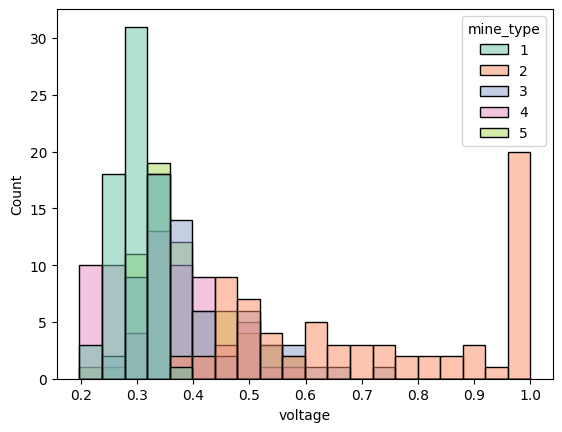

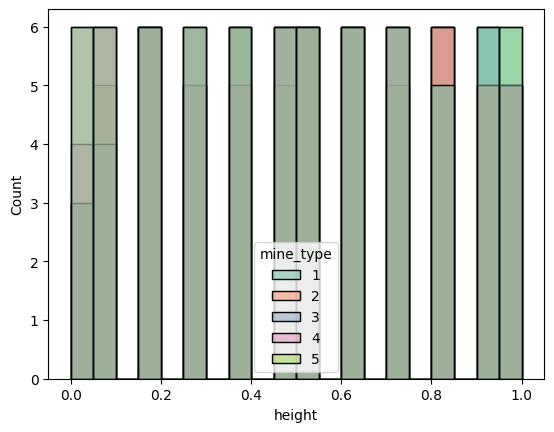

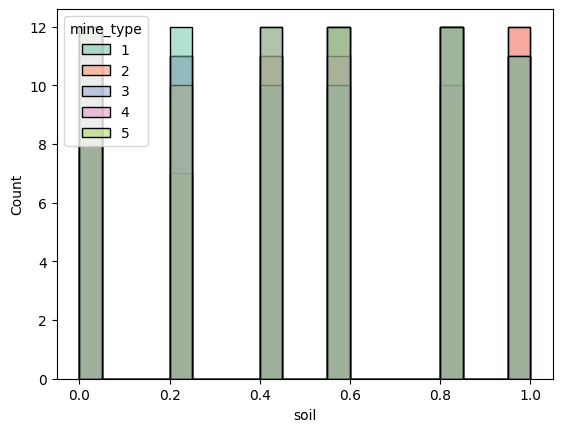

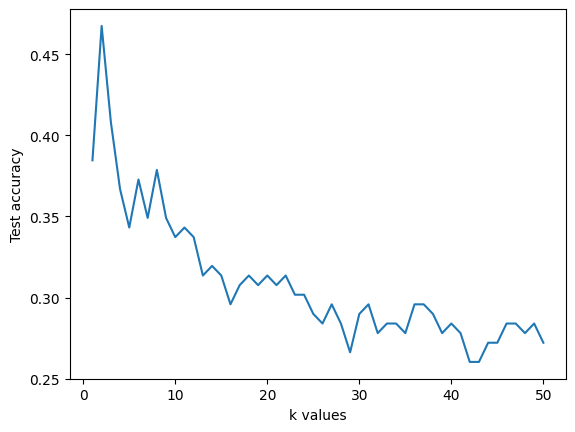

Best k: 2
Accuracy for best k:  0.46745562130177515
Predicted   1   2   3   4  5
Actual                      
1          27   0   5   2  2
2           0  31   2   1  1
3          10   2  10  10  1
4          15   6   3   9  0
5          15   0  10   5  2


In [15]:
from google.colab import drive
drive.mount ('/content/drive')
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

#load data set
df = pd.read_csv('/content/drive/MyDrive/land_mines.csv')


#step 1
#summary statistics
print(df.head())
print(df.info())
print(df.describe())
print('Null counts: ', df.isnull().sum())
print('value counts: ', df['mine_type'].value_counts())

#The data has 338 entries; no missing values;
#voltage (ranges from 0-1), height (ranges from 0-1), and soil (ranges from .2-1) are all floats
#mine_type (int) ranges from 1-5 (categorical)
#the value counts for mine_type are pretty even (ranges from 65-71)

#visualize per feature histogram
#used Set2 to visualize the color differences better
sns.histplot(data=df, x = 'voltage', hue = 'mine_type', bins = 20, palette = 'Set2')
plt.show()
sns.histplot(data=df, x = 'height', hue = 'mine_type', bins = 20, palette = 'Set2')
plt.show()
sns.histplot(data=df, x = 'soil', hue = 'mine_type', bins = 20, palette = 'Set2')
plt.show()

#based on the histograms, voltage for mine_type 1 and 2 appears to be distinct indicators
#based on the confusion table done later, this makes sense for why these 2 mine_types have better
#accuracy values; types 3,4, and 5 overlap signifigantly for voltage
#height and soil show basically no difference in distribution across mine_types


#step 2: split into train/test set
from sklearn.model_selection import train_test_split

x = df[['voltage', 'height', 'soil']]
y = df['mine_type']

#50/50 split, so each mine_type appears in same proportion in both sets (keeps even representation)
#stratify = y ensures training/ test set have same proportion of class labels as original
#random state 65 was selected, resulting in the best value for k to be 2.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.5, random_state = 65, stratify = y)


#need to scale so different categories contribute equal spread
from sklearn.preprocessing import MinMaxScaler
eval_scaler = MinMaxScaler()
x_train = eval_scaler.fit_transform(x_train)
x_test = eval_scaler.transform(x_test)




#3 k-NN classifier
from sklearn.neighbors import KNeighborsClassifier

eval_ks = np.arange(1,51)
accuracies = []

for k in eval_ks:
  eval_candidate = KNeighborsClassifier(n_neighbors =int(k))
  eval_candidate.fit(x_train, y_train)
  eval_prediction = eval_candidate.predict(x_test)
  accuracy = (eval_prediction == y_test).mean()
  accuracies.append(accuracy)


plt.plot(eval_ks, accuracies)
plt.xlabel('k values')
plt.ylabel('Test accuracy')
plt.show()

#best k is where accuracy is highest
best_k = int(eval_ks[np.argmax(accuracies)])
print('Best k:', best_k)

#overall accuracy
accuracy_best_k = max(accuracies)
print('Accuracy for best k: ', accuracy_best_k)

#I selected k by fitting a k-NN classifier for values of k 1-50 on a training set and evaluating
#the accuracy on the test set (avoids the overfititng problem of evaluating the training accuracy)
#With random_state = 65, k=2 was selected as the best k value (the best k value for testing based on the training)
#the accuracy for the best k was 46.7%



#Step 4: confusion table for optimal model
optimal_model = KNeighborsClassifier(n_neighbors=best_k)
optimal_model.fit(x_train, y_train)
eval_prediction_final = optimal_model.predict(x_test)
confusion_table = pd.crosstab(y_test, eval_prediction_final, rownames = ['Actual'], colnames = ['Predicted'])
print(confusion_table)

#the performance was best for type 2 (31/39 correct; little confusion with other types)
#the performance for type 1 was the second best (27/67); confusion with types 3,4, and 5
#notably, there was no confusion between type 1 and type 2
#the performance of types 3, 4, and 5 was poor (signifigant confusion and inaccuracy) in comparision to the other types


#5
#This model tends to over predict type 1, I would instruct someone using this model to be cautious
#about a type 1 prediction. I would say that a type 2 prediction is more trustworthy
#Noteably, since there was no confusion between type 1 and 2, I would say that a type 1 prediction
#may be inaccurate, but it is almost certainly not a type 2 (and vice versa).
#I would also instruct someone using this model to be cautious of types 3, 4, and 5 classification
#In practice, this model is only useful for identifying type 2 mines




---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jackson Gayeski

**Date:** 9/30/26

In [16]:
# Your Phase 1 solution to the problem goes here.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID: affac63
- **AI tool and model used: Claude Opus 5.5

### *Prompts used

1. based off my code and analysis highlight things I may have missed during analysis and note specific improvements to make the overall output more clean
2. improve the wording and accuracy of each step's comments by indicating key changes

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. 1. Your confusion table fractions mix up two different metrics. "27/67" and "31/39" divide by the column totals (everything predicted as that type), which gives precision. But you describe them as "correct out of actual type X," which is recall and uses the row totals. Your test set has 169 rows, not 67+ per class.
2. 2. Type 5 deserves its own callout. Lumping 3/4/5 together hides that type 5 is almost never identified (2/32). Most type 5s get called type 1 (15) or type 3 (10).
3. 3. k=2 is likely causing the type 1 over-prediction. With an even k, the two neighbors often disagree, and sklearn breaks ties by choosing the lowest class label, which is type 1. So some of your 40 misclassified 3/4/5 → 1 predictions may be tie-break artifacts, not real signal. Use odd k values (np.arange(1, 51, 2)) or weights='distance', and mention this in your analysis.
4. 4. Choosing k (and random_state) on the test set is data leakage. Your comment says this avoids overfitting, but tuning k on test accuracy overfits to the test set, so 46.7% is optimistically biased. Picking random_state=65 because it gave a nice k makes it worse. The standard fix is cross-validation on the training set only, then evaluating once on the test set (code below). If your assignment explicitly told you to pick k via test accuracy, that's fine, but acknowledge the bias in a comment.
5. No baseline. With 5 balanced classes, random guessing gives about 20%. Saying 46.7% is roughly 2.3x chance gives the number meaning.
6. 8. Small factual errors in comments:
Soil ranges 0 to 1, not 0.2 to 1 (describe shows min = 0.0).
Height and soil are discrete (height steps by 1/11, soil looks like 6 levels), which is why 20-bin histograms look gappy.
The data is already 0 to 1, so MinMaxScaler barely changes anything. It's fine to keep, but your "need to scale" comment should say it's a safeguard.
A 50/50 split doesn't keep proportions equal; stratify=y does.
7. These comments match your current output (k=2, 46.7%). If you switch to the cross-validation version, rerun it and update the numbers in steps 3–5.

Step 1: summary stats

python
# 338 rows, 4 columns, no missing values
# voltage: float, ~0.20–1.0
# height: float, 0–1, discrete steps of 1/11
# soil: float, 0–1, discrete levels
# all three features are already on a 0–1 scale
# mine_type: int 1–5, categorical
# classes are balanced (65–71 each), so random guessing gives ~20% accuracy

Key changes: soil range corrected (min is 0, not 0.2), discrete features noted, chance baseline added.

Histograms

python
# voltage separates types 1 and 2 from the rest; types 3, 4, and 5 overlap heavily
# height and soil look similar across types on their own, but single-feature
# histograms can't show whether they help in combination with voltage
# this matches the confusion table, where types 1 and 2 are classified best

Key changes: height and soil are no longer called useless, since interactions weren't tested.

Step 2: split and scaling

python
# 50/50 train/test split; stratify=y keeps class proportions equal in both sets
# random_state=65 fixes the split for reproducibility; best k is sensitive to the split

# features are already 0–1, so MinMaxScaler changes little; kept as a safeguard
# so no feature dominates the distance calculation
# scaler is fit on the training set only, so no test information leaks in

Key changes: stratify gets the credit for balanced proportions (not the 50/50 split), the seed isn't described as chosen for a good k, and scaling is described accurately.

Step 3: k-NN

python
# fit k-NN for k = 1–50 and recorded test accuracy for each
# best k = 2, test accuracy = 46.7% (79/169), ~2.3x chance (20%)
# caveat: k was chosen using test accuracy, so 46.7% is optimistic;
# cross-validation on the training set would give an unbiased choice
# caveat: with k=2, ties between the two neighbors go to the lowest label
# (type 1), which likely inflates type 1 predictions

Key changes: accuracy has context, the leakage claim is corrected (the original said this approach avoids overfitting), and the tie-break effect is flagged.

Step 4: confusion table

python
# type 2 performed best: 31/35 actual type 2 correct (89% recall);
# 31/39 type 2 predictions correct (79% precision)
# type 1: 27/36 correct (75% recall), but only 27/67 type 1 predictions were
# correct (40% precision); 40 of 97 actual type 3–5 mines were predicted as type 1
# no confusion between types 1 and 2 in either direction
# types 3 and 4 were poor (30% and 27% recall)
# type 5 was worst: 2/32 correct (6%), mostly predicted as type 1 (15) or 3 (10)

Key changes: the fractions are fixed (the originals mixed up precision and recall), and type 5 is called out separately.

Step 5: interpretation

python
# the model over-predicts type 1: a type 1 prediction is right only 40% of the
# time, so treat it with caution
# type 2 predictions are the most reliable (79% precision, 89% recall)
# types 1 and 2 are never confused, so a type 1 prediction rules out type 2
# and vice versa
# predictions of types 3–5 are unreliable, and type 5 is almost never detected
# in practice, the model is mainly useful for identifying type 2 mines and
# separating type 1 from type 2

Key changes: the claims are backed with numbers, and type 5 is noted as nearly undetectable.

If your assignment's key says type 1 = no mine, add this line to step 5:

python
# since type 1 = no mine, the 40 real mines predicted as type 1 are the most
# dangerous errors: they would be wrongly marked safe



### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept  |cleared up confusion in analysis |
| 2 | Accept | judgement call, but I agree that it improves the analysis|
| 3 |  reject | I find it confusing and think it to be unnecessary |
| 4 |  modify| It makes sense, but this goes against what my instructor told me during studio time|
| 5 | Accept | improves anaylsis  |
| 6 | Accept | fixes minor mistakes  |
| 7 | Accept  | made comments more concise, informative, and readable |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
    voltage    height  soil  mine_type
0  0.338157  0.000000   0.0          1
1  0.320241  0.181818   0.0          1
2  0.287009  0.272727   0.0          1
3  0.256284  0.454545   0.0          1
4  0.262840  0.545455   0.0          1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   voltage    338 non-null    float64
 1   height     338 non-null    float64
 2   soil       338 non-null    float64
 3   mine_type  338 non-null    int64  
dtypes: float64(3), int64(1)
memory usage: 10.7 KB
None
          voltage      height        soil   mine_type
count  338.000000  338.000000  338.000000  338.000000
mean     0.430634    0.508876    0.503550    2.952663
std      0.195819    0.306043    0.344244    1.419703
min      0.197734    

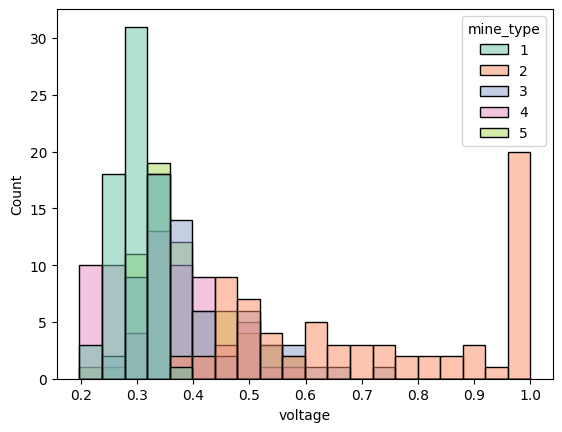

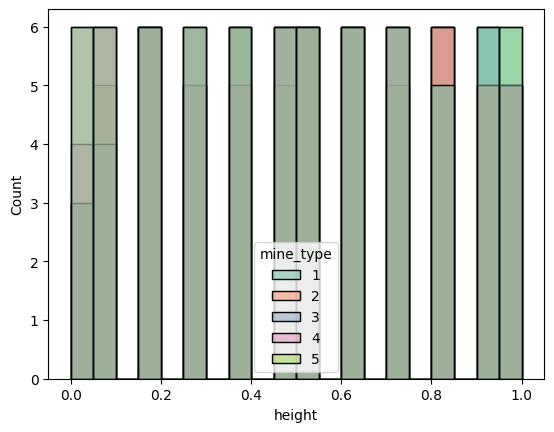

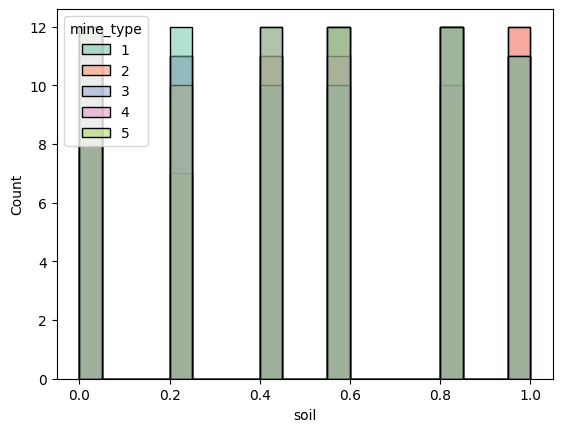

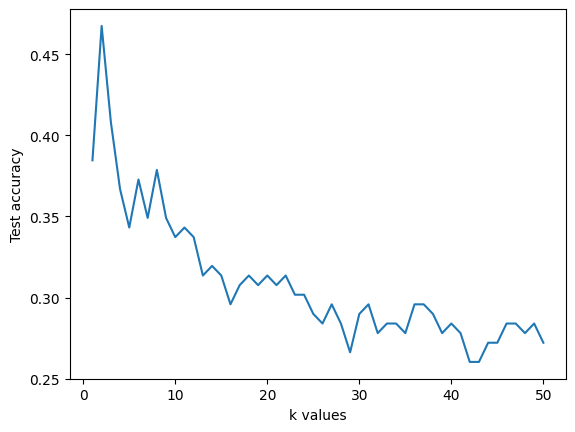

Best k: 2
Accuracy for best k:  0.46745562130177515
Predicted   1   2   3   4  5
Actual                      
1          27   0   5   2  2
2           0  31   2   1  1
3          10   2  10  10  1
4          15   6   3   9  0
5          15   0  10   5  2


In [17]:
from google.colab import drive
drive.mount ('/content/drive')
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

#load data set
df = pd.read_csv('/content/drive/MyDrive/land_mines.csv')


#step 1
#summary statistics
print(df.head())
print(df.info())
print(df.describe())
print('Null counts: ', df.isnull().sum())
print('value counts: ', df['mine_type'].value_counts())

#338 rows, 4 columns, no missing values
#voltage: float, ~0.20-1.0
#height: float, 0-1, discrete steps of 1/11
#soil: float, 0-1, discrete levels
#all three features are already on a 0-1 scale
#mine_type: int 1-5, categorical
#classes are balanced (65-71 each), so random guessing gives ~20% accuracy

#visualize per feature histogram
#used Set2 to make the color differences easier to see
sns.histplot(data=df, x = 'voltage', hue = 'mine_type', bins = 20, palette = 'Set2')
plt.show()
sns.histplot(data=df, x = 'height', hue = 'mine_type', bins = 20, palette = 'Set2')
plt.show()
sns.histplot(data=df, x = 'soil', hue = 'mine_type', bins = 20, palette = 'Set2')
plt.show()

#voltage separates types 1 and 2 from the rest; types 3, 4, and 5 overlap heavily
#height and soil look similar across types on their own, but single-feature
#histograms can't show whether they help in combination with voltage
#this matches the confusion table, where types 1 and 2 are classified best



#step 2: split into train/test set
from sklearn.model_selection import train_test_split

x = df[['voltage', 'height', 'soil']]
y = df['mine_type']

#50/50 train/test split; stratify=y keeps class proportions equal in both sets
#random_state=65 fixes the split for reproducibility; best k is sensitive to the split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.5, random_state = 65, stratify = y)

#features are already 0-1, so MinMaxScaler changes little; kept as a safeguard
#so no feature dominates the distance calculation
#scaler is fit on the training set only, so no test information leaks in
from sklearn.preprocessing import MinMaxScaler
eval_scaler = MinMaxScaler()
x_train = eval_scaler.fit_transform(x_train)
x_test = eval_scaler.transform(x_test)




#3 k-NN classifier
from sklearn.neighbors import KNeighborsClassifier

eval_ks = np.arange(1,51)
accuracies = []

for k in eval_ks:
  eval_candidate = KNeighborsClassifier(n_neighbors =int(k))
  eval_candidate.fit(x_train, y_train)
  eval_prediction = eval_candidate.predict(x_test)
  accuracy = (eval_prediction == y_test).mean()
  accuracies.append(accuracy)


plt.plot(eval_ks, accuracies)
plt.xlabel('k values')
plt.ylabel('Test accuracy')
plt.show()

#best k is where accuracy is highest
best_k = int(eval_ks[np.argmax(accuracies)])
print('Best k:', best_k)

#overall accuracy
accuracy_best_k = max(accuracies)
print('Accuracy for best k: ', accuracy_best_k)

#fit k-NN for k = 1-50 and recorded test accuracy for each
#best k = 2, test accuracy = 46.7% (79/169), ~2.3x chance (20%)
#caveat: k was chosen using test accuracy, so 46.7% is optimistic;
#cross-validation on the training set would give an unbiased choice
#caveat: with k=2, ties between the two neighbors go to the lowest label
#(type 1), which likely inflates type 1 predictions


#Step 4: confusion table for optimal model
optimal_model = KNeighborsClassifier(n_neighbors=best_k)
optimal_model.fit(x_train, y_train)
eval_prediction_final = optimal_model.predict(x_test)
confusion_table = pd.crosstab(y_test, eval_prediction_final, rownames = ['Actual'], colnames = ['Predicted'])
print(confusion_table)

#type 2 performed best: 31/35 actual type 2 correct (89% recall);
#31/39 type 2 predictions correct (79% precision)
#type 1: 27/36 correct (75% recall), but only 27/67 type 1 predictions were
#correct (40% precision); 40 of 97 actual type 3-5 mines were predicted as type 1
#no confusion between types 1 and 2 in either direction
#types 3 and 4 were poor (30% and 27% recall)
#type 5 was worst: 2/32 correct (6%), mostly predicted as type 1 (15) or 3 (10)


#step 5
#the model over-predicts type 1: a type 1 prediction is right only 40% of the
#time, so treat it with caution
#type 2 predictions are the most reliable (79% precision, 89% recall)
#types 1 and 2 are never confused, so a type 1 prediction rules out type 2
#and vice versa
#predictions of types 3-5 are unreliable, and type 5 is almost never detected
#in practice, the model is mainly useful for identifying type 2 mines and
#separating type 1 from type 2




### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The AI mainly improved the accuracy and clarity of my comments on the analysis of the model. It found an error in my interpretation of the confusion table output. Originally, I divided by the column totals (27/67 and 31/39 for example), and described them as correct/actual. The AI also helpfully made a note that I should say something about type 5, which I had previously ignored. Additionally, the suggestion do compare the accuracy output to a baseline (20%) was very helpful for understanding the context of the 46.7% found accuracy. AI also helped with finding minor errors (soil range originally off in my comment). Although I did not notice any apparent mistakes made by the AI, I did find its suggestion to choose k with cross validation and to not use random_state to contradict what my instructor told me in class. It also did not clearly explain how k=2 was biased to type 1. I verified the final solution by rereading through the updated comments, checking the accuracy counts from the confusion table against the accuracy for k=2, and revisited the features histograms to check if my result made sense. The only concern I have is that eliminating random_state results in a different value for the most accurate k. This is likely due to the data set being too small.